In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

from scipy.spatial import distance
import time
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.preprocessing import OneHotEncoder, TargetEncoder

# Настройка визуального оформления графиков
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.autolayout'] = True

# Фиксируем random seed для детерминированности
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
df_airbnb = pd.read_csv('data/AB_NYC_2019.csv')

# Унификация названий колонок (для разных версий выгрузок NYC Airbnb)
rename_dict = {
    'last_review_date': 'last_review',
    'host_listings_count': 'calculated_host_listings_count',
}
df_airbnb = df_airbnb.rename(
    columns={k: v for k, v in rename_dict.items() if k in df_airbnb.columns}
)

# 2. Очистка от NaN и фильтрация нулевых/отрицательных цен
clean_subset = [
    'price',
    'latitude',
    'longitude',
    'last_review',
    'reviews_per_month',
    'name',
]
df_clean = df_airbnb.dropna(subset=clean_subset).copy()
df_clean = df_clean[df_clean['price'] > 0].copy()

# 3. Логарифмирование таргета: сглаживаем сильную правостороннюю асимметрию и тяжелый хвост цен
df_clean['price_log'] = np.log1p(df_clean['price'])

# 4. Исходные (сырые) числовые признаки для бейзлайна
raw_features = [
    'latitude',
    'longitude',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'availability_365',
]

X_raw = df_clean[raw_features]
y = df_clean['price_log']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.3, random_state=RANDOM_STATE
)

# 5. Обучение бейзлайн-модели
baseline_model = LinearRegression()
baseline_model.fit(X_train_raw, y_train)
y_pred_base_log = baseline_model.predict(X_test_raw)

# Метрики бейзлайна
mae_base_log = mean_absolute_error(y_test, y_pred_base_log)
r2_base = r2_score(y_test, y_pred_base_log)
# Перевод ошибки обратно в доллары: expm1(y_pred)
mae_base_dollars = mean_absolute_error(
    np.expm1(y_test), np.expm1(y_pred_base_log)
)

print('=== БЕЙЗЛАЙН-РЕГРЕССИЯ (СЫРЫЕ ПРИЗНАКИ) ===')
print(f'Размер чистой выборки: {len(df_clean)} строк')
print(f'R² на тесте:           {r2_base:.4f}')
print(f'MAE (price_log):       {mae_base_log:.4f}')
print(f'MAE (в долларах $):    ${mae_base_dollars:.2f}')

=== БЕЙЗЛАЙН-РЕГРЕССИЯ (СЫРЫЕ ПРИЗНАКИ) ===
Размер чистой выборки: 38827 строк
R² на тесте:           0.1400
MAE (price_log):       0.4817
MAE (в долларах $):    $67.91


In [3]:
df_fe = df_clean.copy()

# 1. Географический: евклидово расстояние до Таймс-Сквер — чем ближе объект к центру туризма и бизнеса, тем выше ставка аренды.
df_fe['d_center'] = np.sqrt(
    (df_fe['latitude'] - 40.7580) ** 2 + (df_fe['longitude'] - (-73.9855)) ** 2
)

# 2. Временной: давность последнего отзыва — свежие отзывы подтверждают активный спрос и актуальный рыночный прайс, а заброшенные карточки дешевеют.
snapshot_date = pd.to_datetime(df_fe['last_review']).max() + pd.Timedelta(
    days=1
)
df_fe['days_since_last_review'] = (
    snapshot_date - pd.to_datetime(df_fe['last_review'])
).dt.days

# 3. Текстовый: маркер премиум-сегмента — слова 'luxury/studio/spacious/view/penthouse' в названии напрямую сигнализируют о повышенной категории жилья.
luxury_regex = r'\b(?:luxury|studio|spacious|view|penthouse)\b'
df_fe['has_luxury_words'] = (
    df_fe['name']
    .str.lower()
    .str.contains(luxury_regex, regex=True)
    .fillna(False)
    .astype(int)
)

# 4. Бизнес-индикатор: флаг профессионального хоста — управление несколькими объектами говорит о коммерческом бизнесе с алгоритмическим динамическим ценообразованием.
df_fe['is_professional_host'] = (
    df_fe['calculated_host_listings_count'] > 1
).astype(int)

# 5. Категориальный (Ordinal): градация приватности — Shared room (1) < Private room (2) < Entire home/apt (3) отражает монотонный рост комфорта и базовой цены.
room_type_rank_map = {
    'Shared room': 1,
    'Private room': 2,
    'Entire home/apt': 3,
}
df_fe['room_type_rank'] = (
    df_fe['room_type'].map(room_type_rank_map).fillna(1).astype(int)
)

print('Сгенерировано 5 новых признаков успешно.')

Сгенерировано 5 новых признаков успешно.


In [4]:
# 1. Единое разбиение на train и test для чистоты сравнительного эксперимента
train_idx, test_idx = train_test_split(
    df_fe.index, test_size=0.3, random_state=RANDOM_STATE
)

df_train = df_fe.loc[train_idx].copy()
df_test = df_fe.loc[test_idx].copy()

y_train = df_train['price_log']
y_test = df_test['price_log']

# ==============================================================================
# МОДЕЛЬ 1: Baseline (Сырые числовые признаки без доменной обработки)
# ==============================================================================
raw_features = [
    'latitude',
    'longitude',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'availability_365',
]

X_train_m1 = df_train[raw_features]
X_test_m1 = df_test[raw_features]

m1 = LinearRegression().fit(X_train_m1, y_train)
y_pred_m1 = m1.predict(X_test_m1)

# ==============================================================================
# МОДЕЛЬ 2: Feature Engineering (Предметные признаки без категориальных гео-кодировок)
# ==============================================================================
numeric_fe_features = [
    'd_center',
    'days_since_last_review',
    'has_luxury_words',
    'is_professional_host',
    'room_type_rank',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'availability_365',
]

X_train_m2 = df_train[numeric_fe_features]
X_test_m2 = df_test[numeric_fe_features]

m2 = LinearRegression().fit(X_train_m2, y_train)
y_pred_m2 = m2.predict(X_test_m2)

# ==============================================================================
# МОДЕЛЬ 3: Feature Engineering + OHE (Borough) + Target Encoding (Neighbourhood)
# ==============================================================================
# 3.1. One-Hot Encoding для neighbourhood_group (5 боро)
ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
ohe_train = ohe.fit_transform(df_train[['neighbourhood_group']])
ohe_test = ohe.transform(df_test[['neighbourhood_group']])

# 3.2. Target Encoding для neighbourhood (221 район)
te = TargetEncoder(smooth='auto', cv=5, random_state=RANDOM_STATE)
te_train = te.fit_transform(df_train[['neighbourhood']], y_train)
te_test = te.transform(df_test[['neighbourhood']])

# 3.3. Конкатенация признаковых матриц
X_train_m3 = np.hstack([df_train[numeric_fe_features].values, ohe_train, te_train])
X_test_m3 = np.hstack([df_test[numeric_fe_features].values, ohe_test, te_test])

m3 = LinearRegression().fit(X_train_m3, y_train)
y_pred_m3 = m3.predict(X_test_m3)

# ==============================================================================
# СВОДНОЕ СРАВНЕНИЕ ВСЕХ ЭТАПОВ
# ==============================================================================
def calc_metrics(y_true_log, y_pred_log):
  r2 = r2_score(y_true_log, y_pred_log)
  mae_log = mean_absolute_error(y_true_log, y_pred_log)
  mae_dollars = mean_absolute_error(
      np.expm1(y_true_log), np.expm1(y_pred_log)
  )
  return r2, mae_log, mae_dollars


r2_1, mae_log_1, mae_d_1 = calc_metrics(y_test, y_pred_m1)
r2_2, mae_log_2, mae_d_2 = calc_metrics(y_test, y_pred_m2)
r2_3, mae_log_3, mae_d_3 = calc_metrics(y_test, y_pred_m3)

comparison_summary = pd.DataFrame(
    {
        'Этап пайплайна': [
            '1. Baseline (сырые координаты и счетчики)',
            '2. Feature Engineering (числовые фичи)',
            '3. FE + OHE (Borough) + Target Encoding (Районы)',
        ],
        'Кол-во фичей': [
            X_train_m1.shape[1],
            X_train_m2.shape[1],
            X_train_m3.shape[1],
        ],
        'R² (тест)': [r2_1, r2_2, r2_3],
        'MAE (log)': [mae_log_1, mae_log_2, mae_log_3],
        'MAE ($)': [mae_d_1, mae_d_2, mae_d_3],
        'Снижение MAE ($) к Baseline': [
            '0.0%',
            f'{((mae_d_1 - mae_d_2) / mae_d_1) * 100:.1f}%',
            f'{((mae_d_1 - mae_d_3) / mae_d_1) * 100:.1f}%',
        ],
    }
)

print('=== ЭВОЛЮЦИЯ КАЧЕСТВА МОДЕЛИ: ОТ БЕЙЗЛАЙНА К ПОЛНОМУ ПАЙПЛАЙНУ ===')
display(
    comparison_summary.style.format(
        {'R² (тест)': '{:.4f}', 'MAE (log)': '{:.4f}', 'MAE ($)': '${:.2f}'}
    ).background_gradient(subset=['R² (тест)'], cmap='Greens')
)

=== ЭВОЛЮЦИЯ КАЧЕСТВА МОДЕЛИ: ОТ БЕЙЗЛАЙНА К ПОЛНОМУ ПАЙПЛАЙНУ ===


,Этап пайплайна,Кол-во фичей,R² (тест),MAE (log),MAE ($),Снижение MAE ($) к Baseline
0,1. Baseline (сырые координаты и счетчики),7,0.1400,0.4817,$67.91,0.0%
1,2. Feature Engineering (числовые фичи),9,0.5266,0.3378,$52.07,23.3%
2,3. FE + OHE (Borough) + Target Encoding (Районы),14,0.5769,0.3167,$50.05,26.3%


Итоговое число признаков в матрице X: 14
feature_names = ['d_center', 'days_since_last_review', 'has_luxury_words', 'is_professional_host', 'room_type_rank', 'neighbourhood_te', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'availability_365', 'neighbourhood_group_Brooklyn', 'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens', 'neighbourhood_group_Staten Island']


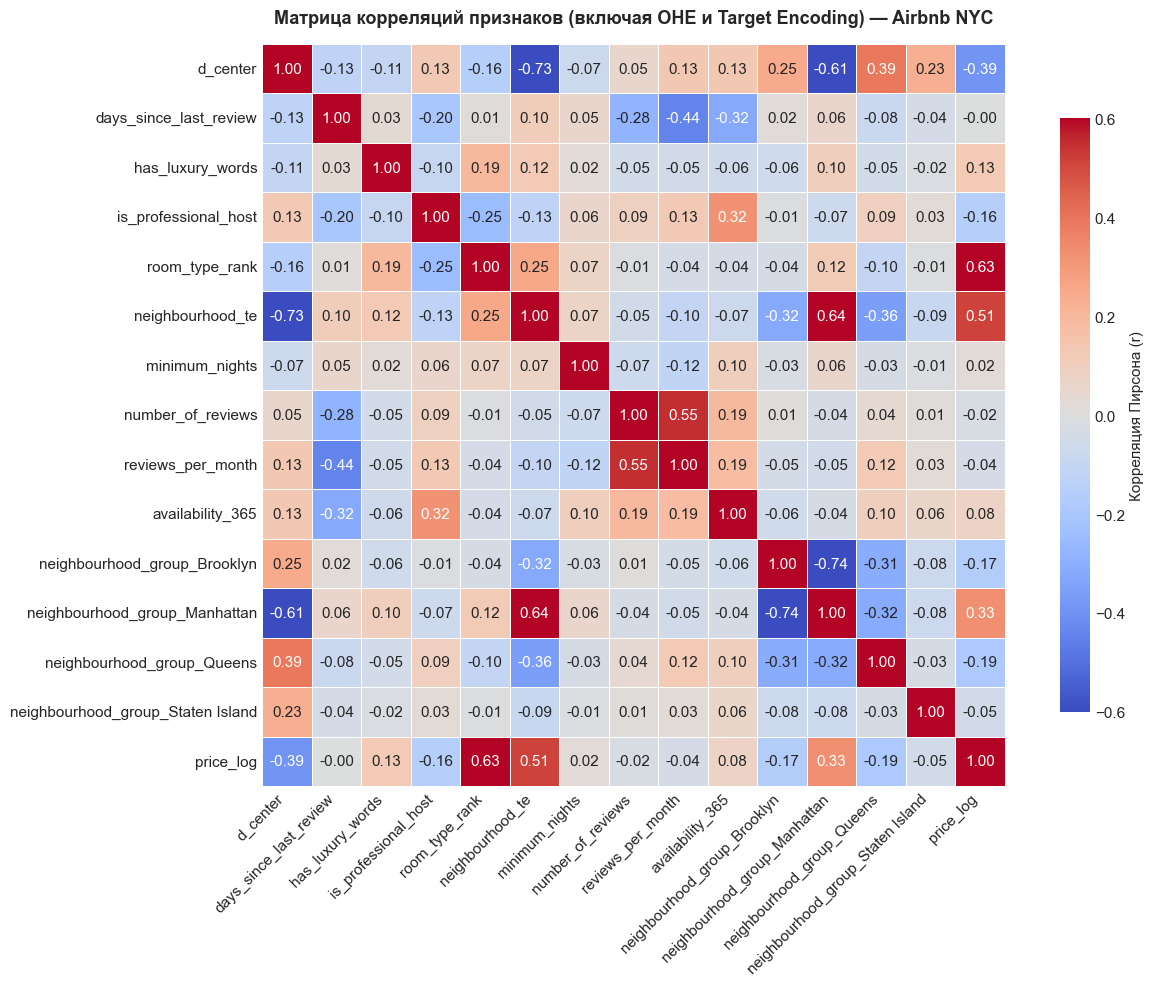

In [5]:
# -------------------------------------------------------------------------
# 0. Кодирование категориальных признаков в df_fe
# -------------------------------------------------------------------------
# One-Hot Encoding для borough (drop_first=True, чтобы избежать dummy-ловушки)
if not any(col.startswith('neighbourhood_group_') for col in df_fe.columns):
  df_fe = pd.get_dummies(
      df_fe, columns=['neighbourhood_group'], drop_first=True, dtype=int
  )

# Target Encoding для neighbourhood (221 район -> 1 числовая колонка)
if 'neighbourhood_te' not in df_fe.columns:
  te = TargetEncoder(smooth='auto', cv=5, random_state=RANDOM_STATE)
  df_fe['neighbourhood_te'] = te.fit_transform(
      df_fe[['neighbourhood']], df_fe['price_log']
  )

# Автоматически собираем имена всех OHE-колонок округов
neighbourhood_groups = [
    col for col in df_fe.columns if col.startswith('neighbourhood_group_')
]

# -------------------------------------------------------------------------
# 1. Формируем единый итоговый список числовых признаков для обучения
# -------------------------------------------------------------------------
feature_names = (
    [
        # Новые сгенерированные признаки (Feature Engineering)
        'd_center',
        'days_since_last_review',
        'has_luxury_words',
        'is_professional_host',
        'room_type_rank',
        # Географический Target Encoding
        'neighbourhood_te',
        # Оставшиеся валидные числовые атрибуты
        'minimum_nights',
        'number_of_reviews',
        'reviews_per_month',
        'availability_365',
    ]
    + neighbourhood_groups
)  # Добавляем OHE-колонки округов

print(f'Итоговое число признаков в матрице X: {len(feature_names)}')
print('feature_names =', feature_names)

# -------------------------------------------------------------------------
# 2. Корреляционный анализ относительно целевой переменной
# -------------------------------------------------------------------------
corr_df = df_fe[feature_names + ['price_log']].corr(method='pearson')

# -------------------------------------------------------------------------
# 3. Визуализация матрицы корреляций (тепловая карта)
# -------------------------------------------------------------------------
# Размер немного увеличен, чтобы 15 признаков не слипались
plt.figure(figsize=(13, 10))

sns.heatmap(
    corr_df,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-0.6,
    vmax=0.6,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8, 'label': 'Корреляция Пирсона (r)'},
)

plt.title(
    'Матрица корреляций признаков (включая OHE и Target Encoding) — Airbnb NYC',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Собираем точный список имен признаков для модели m3
ohe_names = ohe.get_feature_names_out(['neighbourhood_group']).tolist()
m3_feature_names = numeric_fe_features + ohe_names + ['neighbourhood_te']

# 2. Расчет стандартизированной важности (Standardized Coefficients)
# Сырой вес w_j умножаем на стандартное отклонение признака std(x_j),
# чтобы объективно сравнить бинарные флаги, радиальные расстояния и дни.
x_stds = np.std(X_train_m3, axis=0)
raw_weights = m3.coef_
standardized_weights = raw_weights * x_stds

# 3. Формируем датафрейм важности
df_importance = pd.DataFrame(
    {
        'Признак': m3_feature_names,
        'Сырой вес (w)': raw_weights,
        'Std(X)': x_stds,
        'Стандартизированный вклад': standardized_weights,
        'Абсолютная важность': np.abs(standardized_weights),
    }
).sort_values(by='Абсолютная важность', ascending=True)

# 5. Стилизованная таблица для конспекта/ноутбука
print('\n=== ТАБЛИЦА РАНЖИРОВАНИЯ ПРИЗНАКОВ ПО СИЛЕ ВЛИЯНИЯ ===')
display(
    df_importance.sort_values(by='Абсолютная важность', ascending=False)[
        ['Признак', 'Сырой вес (w)', 'Стандартизированный вклад']
    ]
    .reset_index(drop=True)
    .style.format(
        {'Сырой вес (w)': '{:+.4f}', 'Стандартизированный вклад': '{:+.4f}'}
    )
    .bar(
        subset=['Стандартизированный вклад'],
        align='mid',
        color=['#e74c3c', '#2ecc71'],
    )
)


=== ТАБЛИЦА РАНЖИРОВАНИЯ ПРИЗНАКОВ ПО СИЛЕ ВЛИЯНИЯ ===


,Признак,Сырой вес (w),Стандартизированный вклад
0,room_type_rank,+0.6701,+0.3619
1,neighbourhood_te,+0.5710,+0.1916
2,availability_365,+0.0007,+0.0973
3,d_center,-1.3820,-0.0632
4,minimum_nights,-0.0024,-0.0408
5,neighbourhood_group_Manhattan,+0.0726,+0.0359
6,number_of_reviews,-0.0005,-0.0263
7,neighbourhood_group_Brooklyn,+0.0355,+0.0175
8,neighbourhood_group_Queens,+0.0500,+0.0161
9,has_luxury_words,-0.0364,-0.0145
